# Patient-Level Macro Metrics

This notebook calculates class-wise precision, recall, and F1-score, followed by the unweighted macro averages. It uses the current patient-level evaluation report and does not retrain or modify the model.

Macro averaging gives equal importance to the non-sepsis and sepsis classes, even though the dataset is imbalanced.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
REPORT = ROOT / 'reports' / 'final_patient_evaluation_report.json'
report = json.loads(REPORT.read_text(encoding='utf-8'))
print('Report:', REPORT)
print('Model:', report['model'])
print('Threshold:', report['threshold'])
print('Patients:', report['patients'])

Report: e:\Earlysepsispredicton\reports\final_patient_evaluation_report.json
Model: optimized XGBoost
Threshold: 0.6
Patients: 6051


In [2]:
# Confusion matrix layout: [[TN, FP], [FN, TP]]
tn, fp = report['confusion_matrix'][0]
fn, tp = report['confusion_matrix'][1]

class_metrics = {
    'Non-sepsis (0)': {
        'precision': tn / (tn + fn),
        'recall': tn / (tn + fp),
    },
    'Sepsis (1)': {
        'precision': tp / (tp + fp),
        'recall': tp / (tp + fn),
    },
}
for values in class_metrics.values():
    values['f1'] = 2 * values['precision'] * values['recall'] / (values['precision'] + values['recall'])

class_table = pd.DataFrame(class_metrics).T
macro_metrics = class_table[['precision', 'recall', 'f1']].mean()
class_table.style.format('{:.2%}')

,precision,recall,f1
Non-sepsis (0),96.15%,94.37%,95.25%
Sepsis (1),41.91%,51.82%,46.34%


In [3]:
overall = pd.DataFrame({
    'Metric': ['Accuracy', 'Macro precision', 'Macro recall', 'Macro F1-score'],
    'Value': [
        report['metrics']['accuracy'],
        macro_metrics['precision'],
        macro_metrics['recall'],
        macro_metrics['f1'],
    ],
})
display(overall.style.format({'Value': '{:.2%}'}))
non_sepsis = class_table.loc['Non-sepsis (0)']
sepsis = class_table.loc['Sepsis (1)']
print(f'Macro precision = ({non_sepsis.precision:.4f} + {sepsis.precision:.4f}) / 2 = {macro_metrics.precision:.4f}')
print(f'Macro recall = ({non_sepsis.recall:.4f} + {sepsis.recall:.4f}) / 2 = {macro_metrics.recall:.4f}')
print(f'Macro F1 = ({non_sepsis.f1:.4f} + {sepsis.f1:.4f}) / 2 = {macro_metrics.f1:.4f}')

,Metric,Value
0,Accuracy,91.27%
1,Macro precision,69.03%
2,Macro recall,73.09%
3,Macro F1-score,70.80%


Macro precision = (0.9615 + 0.4191) / 2 = 0.6903
Macro recall = (0.9437 + 0.5182) / 2 = 0.7309
Macro F1 = (0.9525 + 0.4634) / 2 = 0.7080


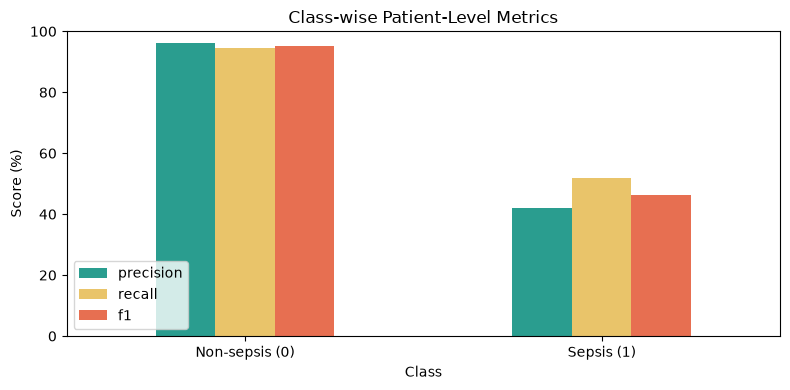

In [4]:
ax = class_table[['precision', 'recall', 'f1']].mul(100).plot(
    kind='bar', figsize=(8, 4), ylim=(0, 100),
    color=['#2a9d8f', '#e9c46a', '#e76f51'],
    title='Class-wise Patient-Level Metrics'
)
ax.set_ylabel('Score (%)')
ax.set_xlabel('Class')
ax.legend(loc='lower left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Interpretation

Macro precision, recall, and F1-score are the simple averages of the corresponding non-sepsis and sepsis class metrics. They are not calculated from accuracy and do not give extra weight to the larger non-sepsis class. The sepsis row is the most important row for assessing whether the system identifies patients who may have sepsis.